# 1.0 · Exploración de los datos de MiBici (oct-2024 a sep-2026)

**Propósito:** entender los datos antes de modelar y justificar las decisiones de la propuesta (rango de fechas,
limpieza, granularidad, rezagos y aproximación del riesgo de P2).

> Este notebook es **solo de exploración**. Toda transformación que se usa para modelar vive en el módulo
> `mibici/` (`dataset.py`, `features.py`) y aquí se importa desde ahí; nada de lo que se decide aquí se
> copia y pega en otro lado.

Prerrequisito: `python -m mibici.dataset ingest` (y `python -m mibici.features build` para la sección de P2).

In [1]:
import os
os.environ.setdefault("LOGURU_LEVEL", "WARNING")  # oculta mensajes informativos del módulo

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mibici import config
from mibici.dataset import load_manifest
from mibici.features import filter_known_stations, load_stations, load_trips
from mibici.plots import PALETTE, INK_2  # aplica el estilo común de gráficas

%matplotlib inline

pd.set_option("display.max_columns", 30)
manifest = load_manifest()
print("Versión de datos:", manifest["data_version"])
pd.Series(manifest["totals"]).drop("station_ids_not_in_nomenclature").to_frame("valor")

Versión de datos: v1.0-202410_202609-226b928677


,valor
months,24
raw_rows,9043925
clean_trips,8770923
stations_in_nomenclature,484
stations_with_trips,472
stations_with_trips_in_nomenclature,470


## 1. Heterogeneidad entre archivos

El reto de la ingesta: los nombres de columnas, la codificación y el formato de fecha pueden cambiar entre
meses. La tabla resume lo que `dataset.py` detectó en cada archivo (sin pasos manuales).

In [2]:
files = pd.DataFrame(manifest["files"])
files["columnas_originales"] = files["original_columns"].apply(lambda c: ", ".join(c))
files["descartados"] = files["dropped"].apply(lambda d: sum(d.values()))
cols = ["month", "encoding", "delimiter", "datetime_format_start", "raw_rows", "processed_rows", "descartados"]
display(files[cols])
print("Variantes de encabezado encontradas:")
for v, n in files["columnas_originales"].value_counts().items():
    print(f"  ({n} archivos) {v}")

,month,encoding,delimiter,datetime_format_start,raw_rows,processed_rows,descartados
0,2024_10,cp1252,",",%d/%m/%Y %H:%M,418690,410956,7734
1,2024_11,cp1252,",",%Y-%m-%d %H:%M:%S,391089,380936,10153
2,2024_12,cp1252,",",%Y-%m-%d %H:%M:%S,340049,331009,9040
3,2025_01,cp1252,",",%Y-%m-%d %H:%M:%S,380184,370902,9282
4,2025_02,cp1252,",",%Y-%m-%d %H:%M:%S,372529,363510,9019
5,2025_03,utf-8-sig,",",%Y-%m-%d %H:%M:%S,405110,394759,10351
6,2025_04,utf-8-sig,",",%Y-%m-%d %H:%M:%S,366193,357056,9137
7,2025_05,utf-8-sig,",",%Y-%m-%d %H:%M:%S,395891,385839,10052
8,2025_06,utf-8-sig,",",%Y-%m-%d %H:%M:%S,356611,346885,9726
9,2025_07,cp1252,",",%Y-%m-%d %H:%M:%S,368186,358411,9775


Variantes de encabezado encontradas:
  (24 archivos) Viaje_Id, Usuario_Id, Genero, Año_de_nacimiento, Inicio_del_viaje, Fin_del_viaje, Origen_Id, Destino_Id


In [3]:
dropped = pd.DataFrame(list(files["dropped"])).sum()
(dropped / files["raw_rows"].sum() * 100).round(3).rename("% de registros crudos").to_frame()

,% de registros crudos
campos_obligatorios_nulos,0.000
trip_id_duplicado,0.008
inicio_fuera_del_mes,0.000
duracion_menor_1_min,3.010
duracion_mayor_24_h,0.000


## 2. Viajes por mes

Viajes limpios: 8,770,923 | estaciones en nomenclatura: 484


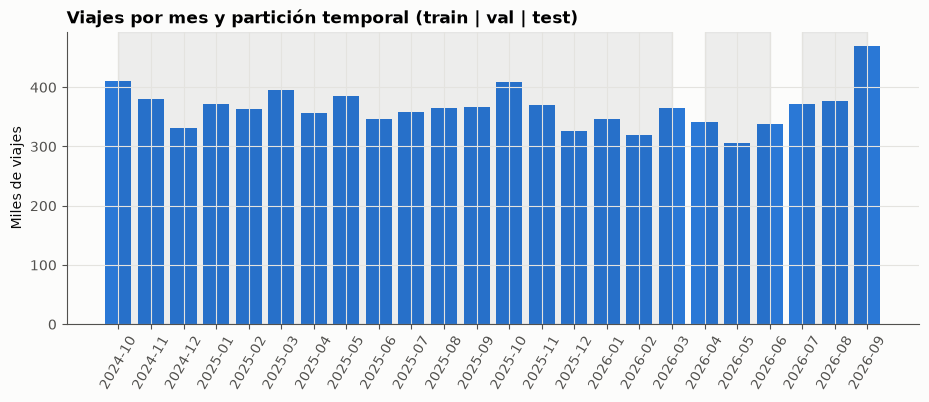

count        24.0
mean     365455.0
std       34521.0
min      305117.0
25%      345413.0
50%      364722.0
75%      377475.0
max      470348.0
dtype: float64

In [4]:
stations = load_stations()
trips = load_trips()
print(f"Viajes limpios: {len(trips):,} | estaciones en nomenclatura: {len(stations)}")
monthly = trips.groupby(trips["start_time"].dt.to_period("M")).size()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(monthly.index.astype(str), monthly.values / 1e3, color=PALETTE[0])
for name, (a, b) in config.SPLITS.items():
    ax.axvspan(pd.Period(a, "M").strftime("%Y-%m"), pd.Period(b, "M").strftime("%Y-%m"), alpha=0.06, color="k")
ax.set_ylabel("Miles de viajes"); ax.set_title("Viajes por mes y partición temporal (train | val | test)", loc="left")
plt.xticks(rotation=60); plt.show()
monthly.describe().round(0)

## 3. Patrón horario y semanal

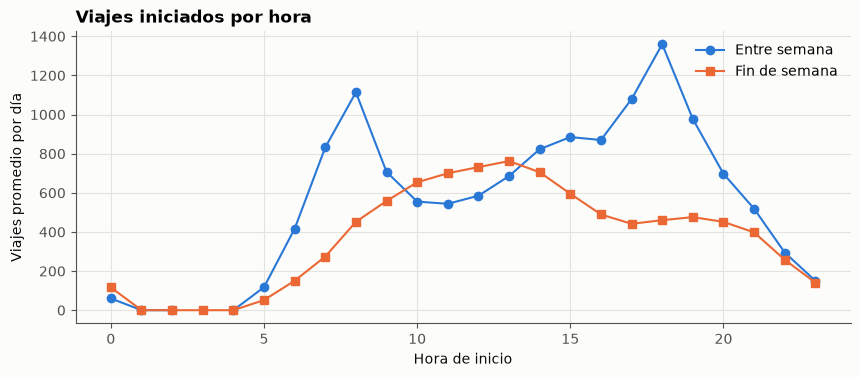

,Lun,Mar,Mié,Jue,Vie,Sáb,Dom
viajes/día,12704.0,13659.0,13653.0,13384.0,12943.0,9427.0,8304.0


In [5]:
t = trips.assign(hour=trips["start_time"].dt.hour, weekend=trips["start_time"].dt.dayofweek >= 5)
n_days = t.groupby("weekend")["start_time"].apply(lambda s: s.dt.normalize().nunique())
prof = t.groupby(["weekend", "hour"]).size().unstack(0) / n_days
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(prof.index, prof[False], marker="o", color=PALETTE[0], label="Entre semana")
ax.plot(prof.index, prof[True], marker="s", color=PALETTE[1], label="Fin de semana")
ax.set_xlabel("Hora de inicio"); ax.set_ylabel("Viajes promedio por día"); ax.legend()
ax.set_title("Viajes iniciados por hora", loc="left"); plt.show()
dow = t.groupby(t["start_time"].dt.dayofweek).size() / t.groupby(t["start_time"].dt.dayofweek)["start_time"].apply(lambda s: s.dt.normalize().nunique())
dow.index = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]; dow.round(0).rename("viajes/día").to_frame().T

**Lectura:** la demanda tiene picos de traslado (mañana y tarde) entre semana y un perfil distinto en fin de
semana; entre la 01:00 y las 05:00 no hay préstamos (sistema cerrado). Esto justifica: (i) modelar P1 por
hora de servicio, (ii) usar calendario y rezagos diarios/semanales, y (iii) definir el día operativo desde
las 05:00 para P2.

## 4. Duración de los viajes

count    8770923.0
mean          11.4
std            8.8
min            1.0
5%             3.0
25%            6.0
50%            9.7
75%           15.0
95%           24.5
99%           33.4
max         1439.2
Name: duration_s, dtype: float64


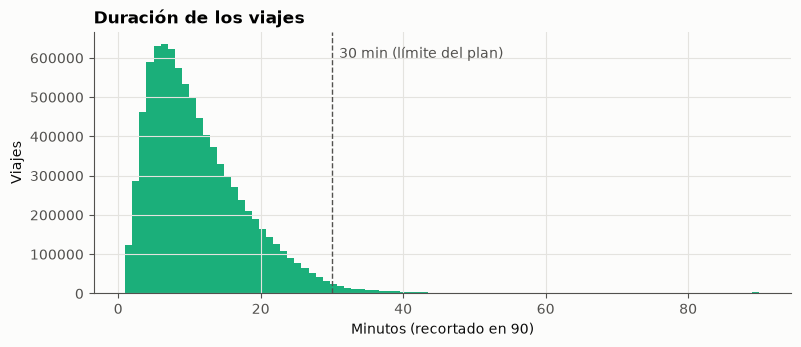

In [6]:
dur = trips["duration_s"] / 60
print(dur.describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(1))
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(dur.clip(upper=90), bins=90, color=PALETTE[2])
ax.axvline(30, color=INK_2, ls="--", lw=1); ax.text(31, ax.get_ylim()[1]*0.9, "30 min (límite del plan)", color=INK_2)
ax.set_xlabel("Minutos (recortado en 90)"); ax.set_ylabel("Viajes"); ax.set_title("Duración de los viajes", loc="left"); plt.show()

## 5. Estaciones: capacidad, volumen y desbalance

Viajes con estación fuera de la nomenclatura: 3,869


,capacidad
count,480.0
mean,17.0
std,3.8
min,11.0
25%,15.0
50%,15.0
75%,19.0
max,39.0


,name,capacity,salidas,llegadas,balance_neto
station_id,,,,,
51,(GDL-049) Lopez Cotilla / Penitenciaría,39,178460.0,221712.0,0.108084
35,(GDL-033) Av. Hidalgo / C. Pedro Loza,15,144703.0,171579.0,0.084975
271,(GDL-198) Av. Alcalde / C. Hospital,31,133491.0,121073.0,-0.048781
11,(GDL-009) Calz. Federalismo/ C. J. Angulo,23,127006.0,117457.0,-0.039061
52,(GDL-050) C.Pedro Moreno /Federalismo,23,112419.0,107817.0,-0.020896
50,(GDL-048) C. Constancio Hernández/ Av. Juaréz,23,106260.0,109452.0,0.014798
54,(GDL-052) Av. Juarez /16 de Septiembre,23,98329.0,103322.0,0.024761
194,(GDL-127) Av. Vallarta / Av. de Los Arcos,19,86693.0,44994.0,-0.316652
38,(GDL-036) C. Marcos Castellanos/ C. Morelos,23,76731.0,78095.0,0.008810


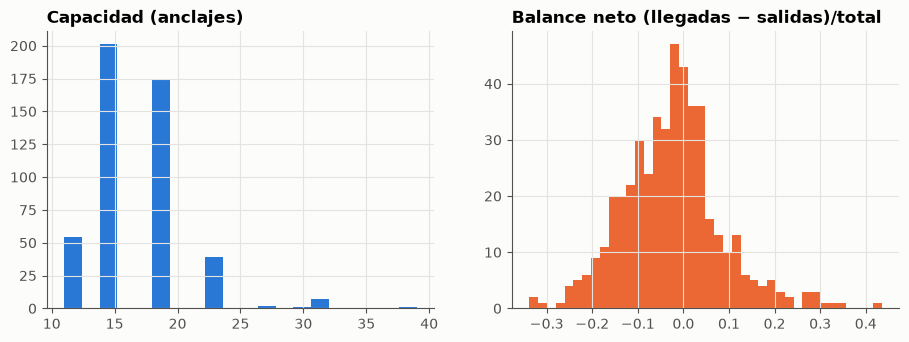

In [7]:
known = filter_known_stations(trips, stations)
dep = known.groupby("origin_station_id").size(); arr = known.groupby("destination_station_id").size()
st = stations.set_index("station_id").join(dep.rename("salidas")).join(arr.rename("llegadas")).fillna({"salidas": 0, "llegadas": 0})
days = (pd.Timestamp(config.DATE_END) - pd.Timestamp(config.DATE_START)).days + 1
st["viajes_dia"] = (st["salidas"] + st["llegadas"]) / days
st["balance_neto"] = (st["llegadas"] - st["salidas"]) / (st["llegadas"] + st["salidas"]).replace(0, np.nan)
print(f"Viajes con estación fuera de la nomenclatura: {len(trips) - len(known):,}")
display(st["capacity"].describe().round(1).to_frame("capacidad"))
display(st.sort_values("salidas", ascending=False).head(10)[["name", "capacity", "salidas", "llegadas", "balance_neto"]])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(st["capacity"].dropna(), bins=20, color=PALETTE[0]); axes[0].set_title("Capacidad (anclajes)", loc="left")
axes[1].hist(st["balance_neto"].dropna(), bins=40, color=PALETTE[1]); axes[1].set_title("Balance neto (llegadas − salidas)/total", loc="left")
plt.show()

**Lectura:** hay estaciones sistemáticamente "origen" (balance negativo) y "destino" (balance positivo):
tienden a vaciarse o a llenarse. Esto motiva P2 y aparece también como variable de P3.

## 6. Autocorrelación de la demanda horaria (justifica los rezagos de P1)

In [8]:
top = dep.nlargest(5).index
lags = [1, 2, 24, 48, 72, 168, 336]
rows = {}
for sid in top:
    hourly = known.loc[known["origin_station_id"] == sid].set_index("start_time").resample("h").size()
    rows[f"estación {sid}"] = {f"{k} h": hourly.autocorr(k) for k in lags}
pd.DataFrame(rows).T.round(3)

,1 h,2 h,24 h,48 h,72 h,168 h,336 h
estación 51,0.662,0.362,0.693,0.592,0.572,0.784,0.770
estación 35,0.816,0.698,0.774,0.700,0.676,0.787,0.755
estación 271,0.693,0.491,0.697,0.589,0.551,0.752,0.729
estación 11,0.678,0.448,0.696,0.580,0.541,0.781,0.762
estación 52,0.705,0.491,0.706,0.610,0.580,0.779,0.741


**Lectura:** en las estaciones con más uso, la autocorrelación más alta está a **168 h** (misma hora de la
semana anterior), seguida de 336 h y 24 h; supera incluso a la de 1 h. Por eso el *baseline* de P1 es el
ingenuo estacional semanal (t − 168 h) y el modelo candidato usa rezagos de 24, 48, 168 y 336 h: todos
≥ 24 h, compatibles con predecir el día siguiente sin fuga de información (el rezago de 1 h no se puede
usar porque la predicción se emite con un día de anticipación).

## 7. Etiqueta aproximada de P2

,tasa de riesgo,filas
split,,
test,0.178604,715063
train,0.262466,3415752
val,0.201413,588667


,proporción
risk_type,
vaciado,0.552
llenado,0.447
ambos,0.001


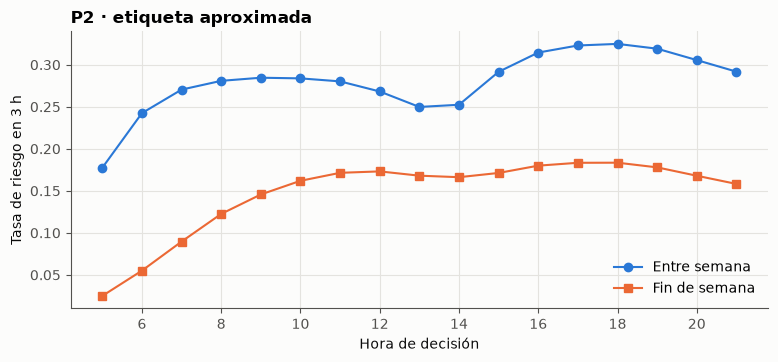

In [9]:
p2 = pd.read_parquet(config.P2_DATASET_PATH, columns=["split", "y", "risk_type", "hour", "is_weekend"])
display(p2.groupby("split")["y"].agg(["mean", "size"]).rename(columns={"mean": "tasa de riesgo", "size": "filas"}))
display(p2.loc[p2["y"] == 1, "risk_type"].value_counts(normalize=True).round(3).to_frame("proporción"))
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, (wk, lab) in enumerate([(0, "Entre semana"), (1, "Fin de semana")]):
    r = p2[p2["is_weekend"] == wk].groupby("hour")["y"].mean(); ax.plot(r.index, r.values, marker="os"[i], color=PALETTE[i], label=lab)
ax.set_xlabel("Hora de decisión"); ax.set_ylabel("Tasa de riesgo en 3 h"); ax.legend(); ax.set_title("P2 · etiqueta aproximada", loc="left"); plt.show()

**Lectura:** la clase positiva es minoritaria, por lo que la exactitud (*accuracy*) sería engañosa; se usan
PR-AUC, exhaustividad y F2. El riesgo crece a lo largo del día, coherente con la acumulación de desbalances
desde la apertura.

## 8. Decisiones que se trasladan al módulo

| Hallazgo | Decisión | Dónde |
|---|---|---|
| Columnas, codificación y fechas varían entre archivos | Detección automática y esquema canónico | `dataset.read_raw_trips` |
| Viajes < 1 min o > 24 h | Reglas de limpieza con conteo en el manifiesto | `dataset.clean_trips` |
| Sin servicio 01:00–05:00 | Día operativo desde las 05:00; P1 solo en horas de servicio | `features.add_calendar_features` |
| Alta autocorrelación a 24 h y 168 h | Rezagos 24/48/168/336 h y promedios a la misma hora | `features.add_lag_features`, `add_same_hour_mean` |
| Estaciones origen/destino | Ocupación estimada y balance neto | `features.estimate_occupancy`, `station_usage_profiles` |
| Clase de riesgo minoritaria | PR-AUC, recall, F2; umbral elegido en validación | `modeling/train.py` |